# Task 1.2 – Random Indexing with permutations, evaluated on TOEFL
Christos Palantzidis · D7041E Lab 2

Same method as the provided RI/main.py: sparse random index vectors, frequent words ignored,
left neighbours rotated by −1 and right neighbours by +1 ("directional" permutation).
Run the cells from top to bottom (≈ 5 minutes in total).

In [1]:
# Install NLTK (lemmatizer), pandas (tables) and matplotlib (plots).
%pip install -q nltk pandas matplotlib

In [2]:
# Import the Colab helper that connects this notebook to Google Drive.
from google.colab import drive
# Import Path to build file and folder paths.
from pathlib import Path
# Import ZipFile to read files directly from NLP.zip.
from zipfile import ZipFile

# Connect Google Drive; Colab asks for permission the first time.
drive.mount("/content/drive")
# The Drive folder that contains NLP.zip.
drive_folder = Path("/content/drive/MyDrive/Lab2 advanced AI")
# Full path of the ZIP file inside that folder.
zip_path = drive_folder / "NLP.zip"
# Stop with a clear message if the ZIP file is not where we expect it.
if not zip_path.is_file():
    # Show the exact path that was checked.
    raise FileNotFoundError(f"Could not find the ZIP file at {zip_path}")

# Folder on Colab's fast local disk where the files are extracted.
local_folder = Path("/content/lab2")
# Open the ZIP file (it is closed automatically at the end of the block).
with ZipFile(zip_path) as archive:
    # Extract the lemmatized TASA corpus from the RI project folder.
    training_file = Path(archive.extract("Part2_NLP/RI/lemmatized.text", path=local_folder))
    # Extract the 80 TOEFL synonym questions from the RI project folder.
    toefl_file = Path(archive.extract("Part2_NLP/RI/new_toefl.txt", path=local_folder))
# Confirm that both files are ready.
print("Files ready:", training_file.name, toefl_file.name)

Mounted at /content/drive
Files ready: lemmatized.text new_toefl.txt


In [3]:
# Import NLTK, which provides the WordNet lemmatizer.
import nltk
# Import NumPy for vectors, random numbers and fast array operations.
import numpy as np
# Import the lemmatizer class.
from nltk.stem import WordNetLemmatizer

# Download the WordNet dictionary needed by the lemmatizer (quietly).
nltk.download("wordnet", quiet=True)
# Create one lemmatizer object and reuse it for all words.
lemmatizer = WordNetLemmatizer()


# Define a function that turns a word into its base form (lemma).
def normalize_word(word):
    # Try the word as a verb, then as a noun, then as an adjective (as in the course code).
    for pos in ("v", "n", "a"):
        # Each step starts from the result of the previous step.
        word = lemmatizer.lemmatize(word, pos=pos)
    # Return the final base form, e.g. "provisions" -> "provision".
    return word


# Open the TOEFL file; each line = query word, correct synonym, 3 wrong alternatives.
with toefl_file.open(encoding="utf-8") as f:
    # Lemmatize the 5 words of every non-empty line and keep them as one question.
    questions = [[normalize_word(w) for w in line.split()] for line in f if line.strip()]
# Confirm that all 80 questions were loaded.
print("TOEFL questions loaded:", len(questions))

# Dictionary word -> integer id (every new word gets the next free number).
vocab = {}
# List that will hold the whole corpus as a sequence of word ids.
ids = []
# Open the corpus.
with training_file.open(encoding="utf-8") as f:
    # Read it line by line.
    for line in f:
        # Look at every word of the line.
        for w in line.split():
            # Add the id of the word (a new id is created the first time we see it).
            ids.append(vocab.setdefault(w, len(vocab)))
# THE FIX FOR window_size: all lines are joined into ONE continuous stream of tokens,
# so the neighbours of position i are simply i-1..i-W and i+1..i+W for any window size W.
ids = np.array(ids, dtype=np.int32)
# Count how many times each word occurs in the corpus.
counts = np.bincount(ids, minlength=len(vocab))
# Show the size of the corpus and of the vocabulary.
print(f"{len(ids):,} tokens, {len(vocab):,} distinct words")

# All distinct words that appear in the TOEFL questions.
toefl_words = sorted({w for q in questions for w in q})
# Keep only the TOEFL words that actually occur in the corpus.
toefl_in_corpus = [w for w in toefl_words if w in vocab]
# Their ids: these are the only words we build embeddings for (as in the course code).
target_ids = np.array([vocab[w] for w in toefl_in_corpus])
# Show how many TOEFL words we need.
print(f"TOEFL words: {len(toefl_words)} (in the corpus: {len(toefl_in_corpus)})")

TOEFL questions loaded: 80
10,766,283 tokens, 70,583 distinct words
TOEFL words: 385 (in the corpus: 378)


In [4]:
# Words that occur at least this often get an empty index vector (like stop-words).
THRESHOLD = 15000
# Number of +1 entries (and of -1 entries) in each random index vector.
ONES = 2


# Create one sparse random index vector per vocabulary word.
def make_index_vectors(n_words, dim, rng):
    # Draw 2*ONES random positions for every word (only the non-zero positions are stored).
    pos = rng.integers(0, dim, size=(n_words, 2 * ONES))
    # Repeat until no word has the same position twice.
    while True:
        # Sort the positions of every word so repeated positions become neighbours.
        s = np.sort(pos, axis=1)
        # Find the words that have a repeated position.
        bad = np.nonzero((s[:, 1:] == s[:, :-1]).any(axis=1))[0]
        # Stop when every word has distinct positions.
        if len(bad) == 0:
            break
        # Draw new positions only for those words.
        pos[bad] = rng.integers(0, dim, size=(len(bad), 2 * ONES))
    # Signs of the non-zeros: ONES times -1 and ONES times +1 (like get_random_word_vector).
    sign = np.tile(np.array([-1] * ONES + [1] * ONES, dtype=np.int8), (n_words, 1))
    # Frequent words get only zeros, so they do not contribute to any embedding.
    sign[counts >= THRESHOLD] = 0
    # Return positions and signs: together they describe every index vector.
    return pos, sign


# Build the embeddings of the chosen target words with a window of `window` words per side.
def train(target_ids, pos, sign, dim, window):
    # Number of tokens in the corpus.
    n = len(ids)
    # Map each target word id to its row in the embedding matrix.
    row_of = {w: r for r, w in enumerate(target_ids)}
    # Boolean table: True for the ids of target words.
    is_target = np.zeros(pos.shape[0], dtype=bool)
    # Mark the target words.
    is_target[target_ids] = True
    # Corpus positions where a target word occurs.
    occ = np.nonzero(is_target[ids])[0]
    # Embedding row for each of these occurrences.
    rows = np.array([row_of[w] for w in ids[occ]], dtype=np.int64)
    # Start every embedding as a zero vector.
    space = np.zeros((len(target_ids), dim))
    # Distance of the neighbour: 1, 2, ..., window.
    for k in range(1, window + 1):
        # Left neighbours (direction -1) are rotated by -1, right neighbours (+1) by +1.
        for direction, shift in ((-1, -1), (+1, +1)):
            # Corpus position of the neighbour for every occurrence.
            nb = occ + direction * k
            # Keep only neighbours that lie inside the corpus.
            ok = (nb >= 0) & (nb < n)
            # Word ids of these neighbours.
            ctx = ids[nb[ok]]
            # Rotating a sparse vector = moving its non-zero positions (wrapping around with % dim).
            cols = (pos[ctx] + shift) % dim
            # Embedding row of every non-zero (each neighbour has 2*ONES non-zeros).
            r = np.repeat(rows[ok], pos.shape[1])
            # Add the signs (+1/-1) at the rotated positions; add.at handles repeated cells correctly.
            np.add.at(space, (r, cols.ravel()), sign[ctx].ravel())
    # Return the embeddings and the number of target occurrences processed.
    return space, len(occ)


# Define the cosine similarity between two vectors.
def cosine(x, y):
    # Dot product divided by the product of the two vector lengths.
    return float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))


# TOEFL test with the same rules as the provided RI/main.py.
def evaluate_toefl(space, dim, seed):
    # Random generator for words that got no representation.
    rng = np.random.default_rng(seed)
    # Copy every learned vector into a dictionary word -> vector.
    vec = {w: space[r].copy() for r, w in enumerate(toefl_in_corpus)}
    # Start counting correct answers and skipped questions from zero.
    correct, skipped = 0, 0
    # Split every question into the query word and its 4 alternatives.
    for query, *options in questions:
        # A query word without a (non-zero) vector cannot be tested...
        if query not in vec or not vec[query].any():
            # ...so the question is skipped and counts as wrong.
            skipped += 1
            # Go to the next question.
            continue
        # Look at every alternative.
        for w in options:
            # An alternative without a learned vector...
            if w not in vec or not vec[w].any():
                # ...gets a random vector, as in the course code.
                vec[w] = rng.standard_normal(dim)
        # Cosine similarity between the query and each of the 4 alternatives.
        scores = [cosine(vec[query], vec[w]) for w in options]
        # The first alternative is always the correct synonym in new_toefl.txt.
        if int(np.argmax(scores)) == 0:
            # The model chose the correct synonym.
            correct += 1
    # Return the number of correct answers and of skipped questions.
    return correct, skipped

In [5]:
# Import a precise timer to measure the training time.
from time import perf_counter
# Import pandas to show the results as tables.
import pandas as pd

# Five different random seeds = five independent runs per setting.
seeds = (17, 23, 31, 47, 59)


# Run one experiment for one dimension, window and seed and return its results.
def run(dim, window, seed):
    # Random generator for this run.
    rng = np.random.default_rng(seed)
    # New random index vectors for the whole vocabulary.
    pos, sign = make_index_vectors(len(vocab), dim, rng)
    # Start the timer just before training.
    start = perf_counter()
    # Build the embeddings of the TOEFL words.
    space, n_occ = train(target_ids, pos, sign, dim, window)
    # Stop the timer.
    train_s = perf_counter() - start
    # Run the TOEFL test.
    correct, skipped = evaluate_toefl(space, dim, seed)
    # Accuracy in percent, always divided by all 80 questions.
    acc = 100 * correct / len(questions)
    # Print the result immediately.
    print(f"window={window} d={dim:6d} seed={seed} correct={correct}/80 accuracy={acc:.2f}% "
          f"skipped={skipped} time={train_s:.2f}s", flush=True)
    # Return the settings and results of this run.
    return {"window": window, "dimension": dim, "seed": seed, "correct_out_of_80": correct,
            "skipped": skipped, "accuracy_pct": acc, "training_seconds": train_s,
            "target_occurrences": n_occ}


# Experiment A: three (plus one larger) dimensionalities, window 2, 5 seeds each.
dim_results = pd.DataFrame([run(d, 2, s) for d in (1000, 4000, 10000, 30000) for s in seeds])
# Experiment B: the fixed code with windows 1-4 at d = 4000, 5 seeds each.
win_results = pd.DataFrame([run(4000, w, s) for w in (1, 2, 3, 4) for s in seeds])

window=2 d=  1000 seed=17 correct=55/80 accuracy=68.75% skipped=1 time=1.60s
window=2 d=  1000 seed=23 correct=54/80 accuracy=67.50% skipped=1 time=1.12s
window=2 d=  1000 seed=31 correct=54/80 accuracy=67.50% skipped=1 time=1.07s
window=2 d=  1000 seed=47 correct=52/80 accuracy=65.00% skipped=1 time=1.10s
window=2 d=  1000 seed=59 correct=61/80 accuracy=76.25% skipped=1 time=1.09s
window=2 d=  4000 seed=17 correct=56/80 accuracy=70.00% skipped=1 time=1.17s
window=2 d=  4000 seed=23 correct=59/80 accuracy=73.75% skipped=1 time=1.21s
window=2 d=  4000 seed=31 correct=59/80 accuracy=73.75% skipped=1 time=1.21s
window=2 d=  4000 seed=47 correct=53/80 accuracy=66.25% skipped=1 time=1.23s
window=2 d=  4000 seed=59 correct=58/80 accuracy=72.50% skipped=1 time=2.13s
window=2 d= 10000 seed=17 correct=61/80 accuracy=76.25% skipped=1 time=2.20s
window=2 d= 10000 seed=23 correct=61/80 accuracy=76.25% skipped=1 time=1.27s
window=2 d= 10000 seed=31 correct=60/80 accuracy=75.00% skipped=1 time=1.28s

,window,dimension,seed,correct_out_of_80,skipped,accuracy_pct,training_seconds,target_occurrences
0,2,1000,17,55,1,68.75,1.60,417254
1,2,1000,23,54,1,67.50,1.12,417254
2,2,1000,31,54,1,67.50,1.07,417254
3,2,1000,47,52,1,65.00,1.10,417254
4,2,1000,59,61,1,76.25,1.09,417254
5,2,4000,17,56,1,70.00,1.17,417254
6,2,4000,23,59,1,73.75,1.21,417254
7,2,4000,31,59,1,73.75,1.21,417254
8,2,4000,47,53,1,66.25,1.23,417254
9,2,4000,59,58,1,72.50,2.13,417254


,dimension,mean_accuracy_pct,sd_accuracy_pct,mean_training_sec
0,1000,69.00,4.28,1.19
1,4000,71.25,3.19,1.39
2,10000,74.75,1.63,1.45
3,30000,74.75,2.71,1.68


,window,mean_accuracy_pct,sd_accuracy_pct
0,1,73.00,1.90
1,2,71.25,3.19
2,3,63.50,2.24
3,4,61.75,1.43


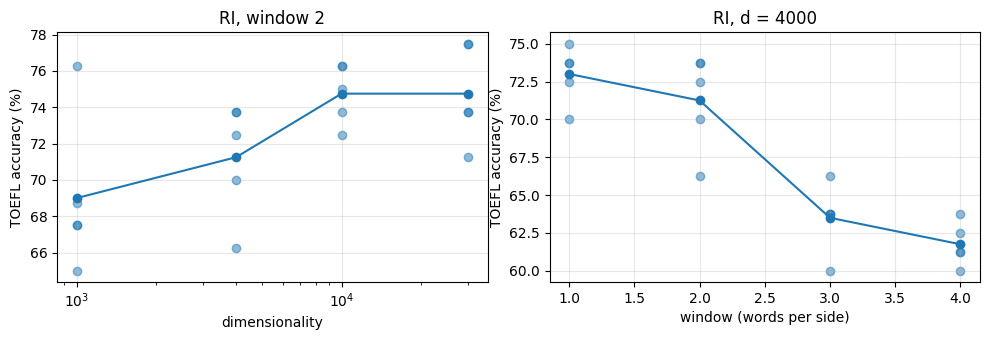

Saved to: /content/drive/MyDrive/Lab2 advanced AI


In [6]:
# Import matplotlib to draw the plots.
import matplotlib.pyplot as plt

# Summary per dimension: mean and spread of the accuracy, mean training time.
dim_summary = dim_results.groupby("dimension", as_index=False).agg(
    mean_accuracy_pct=("accuracy_pct", "mean"),      # average accuracy
    sd_accuracy_pct=("accuracy_pct", "std"),         # spread between runs
    mean_training_sec=("training_seconds", "mean"),  # average training time
)
# Summary per window size.
win_summary = win_results.groupby("window", as_index=False).agg(
    mean_accuracy_pct=("accuracy_pct", "mean"),      # average accuracy
    sd_accuracy_pct=("accuracy_pct", "std"),         # spread between runs
)
# Show all runs of experiment A.
display(dim_results.round(2))
# Show the summary of experiment A.
display(dim_summary.round(2))
# Show the summary of experiment B.
display(win_summary.round(2))

# Two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
# Left plot: one dot per run against the dimension.
axes[0].scatter(dim_results["dimension"], dim_results["accuracy_pct"], alpha=.5)
# Line through the means.
axes[0].plot(dim_summary["dimension"], dim_summary["mean_accuracy_pct"], "o-")
# Logarithmic x-axis.
axes[0].set_xscale("log")
# Axis labels and title.
axes[0].set_xlabel("dimensionality"); axes[0].set_ylabel("TOEFL accuracy (%)"); axes[0].set_title("RI, window 2")
# Right plot: one dot per run against the window size.
axes[1].scatter(win_results["window"], win_results["accuracy_pct"], alpha=.5)
# Line through the means.
axes[1].plot(win_summary["window"], win_summary["mean_accuracy_pct"], "o-")
# Axis labels and title.
axes[1].set_xlabel("window (words per side)"); axes[1].set_ylabel("TOEFL accuracy (%)"); axes[1].set_title("RI, d = 4000")
# Light grid lines on both plots.
for ax in axes:
    ax.grid(alpha=.3)
# Avoid overlapping labels.
plt.tight_layout()
# Save the figure in the Drive folder.
plt.savefig(drive_folder / "task1_2_random_indexing.png", dpi=150)
# Display the figure.
plt.show()

# Save both result tables as CSV files in the Drive folder.
dim_results.to_csv(drive_folder / "task1_2_ri_dimensions.csv", index=False)
win_results.to_csv(drive_folder / "task1_2_ri_windows.csv", index=False)
# Confirm where the files were saved.
print("Saved to:", drive_folder)

In [7]:
# Computational cost: build embeddings for ALL words of the vocabulary (not only TOEFL words).
all_ids = np.arange(len(vocab))
# Measure it at two dimensionalities.
for dim in (1000, 4000):
    # New random index vectors.
    pos, sign = make_index_vectors(len(vocab), dim, np.random.default_rng(0))
    # Start the timer.
    start = perf_counter()
    # Train embeddings for every word (every token of the corpus is a focus word).
    space, n_occ = train(all_ids, pos, sign, dim, window=2)
    # Print the time and the number of focus-word occurrences.
    print(f"ALL {len(vocab):,} words, d={dim}: {perf_counter() - start:.1f}s "
          f"({n_occ:,} focus-word occurrences)")
    # Free the memory of the large matrix before the next run.
    del space

ALL 70,583 words, d=1000: 34.8s (10,766,283 focus-word occurrences)
ALL 70,583 words, d=4000: 45.8s (10,766,283 focus-word occurrences)
